# Självstudieövningar – Vecka 4

De här övningarna är till för att du ska repetera och befästa det vi har gått igenom under veckan samt introducera några nya begrepp på ett tryggt sätt.

Det innebär att vissa av uppgifterna kan du behöva söka efter information själv hur du löser. Här kan du använda Google eller AI om du vill men Python-dokumentationen är din bästa vän när du lär dig.

Länk: https://docs.python.org/3.13/

Läs först igenom vad som ska göras i respektive uppgift och fyll sedan i kodblocket nedanför, eller gör uppgiften i en separat fil.

**Detta lämnas inte in för rättning.** Arbeta i din egen takt, testa dig fram, använd dokumentationen när du kör fast och ta med eventuella frågor till nästa lektionstillfälle.

## (Kör först) Skapa veckans dataset

In [4]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)  # reproducible
n = 300
cities = np.array(["Göteborg","Malmö","Stockholm","Uppsala"])
genders = np.array(["F","M"])

age = rng.integers(18, 65, size=n)
gender = rng.choice(genders, size=n)
city = rng.choice(cities, size=n, p=[0.3,0.2,0.4,0.1])
steps = rng.normal(8000, 2000, size=n).clip(1000, 20000).astype(int)
sleep_hours = rng.normal(7.0, 1.2, size=n).clip(3.5, 11.0)
screen_time = rng.normal(4.0, 1.5, size=n).clip(0.5, 12.0)
calories = rng.normal(2200, 450, size=n).clip(1000, 4000)

# relationer: fler steg → lägre skärmtid, högre kalorier
screen_time = np.clip(screen_time - (steps - 8000)/8000 * 0.6, 0.5, 12.0)
calories    = np.clip(calories    + (steps - 8000)/8000 * 120, 1000, 4000)

df = pd.DataFrame({
    "age": age,
    "gender": gender,
    "city": city,
    "steps": steps,
    "sleep_hours": np.round(sleep_hours,2),
    "screen_time": np.round(screen_time,2),
    "calories": np.round(calories,0).astype(int)
})

# ca 2% saknade värden (NaN)
mask = rng.random(size=df.shape) < 0.02
for (r, c), m in np.ndenumerate(mask):
    if m:
        df.iat[r, c] = np.nan

df.to_csv("week4_data.csv", index=False)
print("Skapade week4_data.csv med", len(df), "rader.")

Skapade week4_data.csv med 300 rader.


### Om datasettet (week4_data.csv)
Det här är ett **syntetiskt** dataset från en fiktiv hälso-/livsstilsapp. Varje rad är en person/dag.

| Kolumn | Typ | Beskrivning | Ungefärligt intervall |
|---|---|---|---|
| `age` | int | Ålder | 18–64 |
| `gender` | kategori | Kön (F/M) | – |
| `city` | kategori | Stad | Göteborg, Malmö, Stockholm, Uppsala |
| `steps` | int | Antal steg/dygn | ~1 000–20 000 |
| `sleep_hours` | float | Sömn/dygn | ~3.5–11 |
| `screen_time` | float | Skärmtid/dygn | ~0.5–12 |
| `calories` | int | Energiförbrukning | ~1 000–4 000 |

**Noteringar:** Fast seed för reproducerbarhet, ~2% NaN, svag relation: fler `steps` → lägre `screen_time` men högre `calories` i snitt.

### Snabb kontroll
- Läs in `week4_data.csv` i `df`.
- Visa `df.head()` för att se de första raderna.
- Visa datatyper med `df.info()`.
- Räkna saknade värden per kolumn med en metod i Pandas.
- Skriv en kort kommentar (i en kodkommentar) om vilken kolumn som verkar ha flest NaN.

In [4]:
df = pd.read_csv("week4_data.csv")
print(df.head())
print()
print(df.info())
print()
print(df.isna().sum()) # age seems to have most NaN values


    age gender       city    steps  sleep_hours  screen_time  calories
0  22.0      F  Stockholm  10495.0         6.73         4.04    1582.0
1  54.0      M   Göteborg   7494.0         6.88         4.59    2017.0
2   NaN      F  Stockholm   8726.0         6.97         4.57    2979.0
3  38.0      M  Stockholm   3180.0         7.27         2.38    2330.0
4  38.0      M  Stockholm   5687.0         8.14         5.46    2419.0

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   age          291 non-null    float64
 1   gender       296 non-null    str    
 2   city         296 non-null    str    
 3   steps        297 non-null    float64
 4   sleep_hours  293 non-null    float64
 5   screen_time  292 non-null    float64
 6   calories     296 non-null    float64
dtypes: float64(5), str(2)
memory usage: 16.5 KB
None

age            9
gender         4
city         

## Block A – NumPy

### Uppgift 1 – Array-grunder
Skapa en följd av heltal och gör enkla operationer med **vektoriserad** aritmetik.
- Skapa en 1D-array med heltal 0..19.
- Skapa en ny array med kvadraterna av dessa tal (utan loop).
- Plocka ut de tal som är delbara med 3 genom ett boolean-filter.

In [5]:
array1 = np.arange(20)
array2 = array1 **2
print(array2)
mask = array1 % 3 == 0
print(array1[mask])

[  0   1   4   9  16  25  36  49  64  81 100 121 144 169 196 225 256 289
 324 361]
[ 0  3  6  9 12 15 18]


### Uppgift 2 – Slicing & reshaping
Träna indexering i 2D.
- Skapa en array med tal 1..24.
- Forma om till en 4×6-matris.
- Plocka ut kolumnerna 2–4 (inklusive) och raderna 2–3 (inklusive) via slicing.

In [6]:
array3 = np.arange(1, 25).reshape(4, 6)
print(array3)
print()
print(array3[1:3, 1:4])

[[ 1  2  3  4  5  6]
 [ 7  8  9 10 11 12]
 [13 14 15 16 17 18]
 [19 20 21 22 23 24]]

[[ 8  9 10]
 [14 15 16]]


### Uppgift 3 – Broadcasting
Använd broadcasting för att kombinera en matris och en vektor.
- Skapa en 3×3-matris med ettor.
- Skapa en vektor `[10, 20, 30]`.
- Lägg till vektorn **radvis** till matrisen och skriv ut resultatet.

In [7]:
matrix1 = np.zeros((3, 3))
vector1 = [10, 20, 30]
print(matrix1 + vector1)


[[10. 20. 30.]
 [10. 20. 30.]
 [10. 20. 30.]]


### Uppgift 4 – Felsökning (listor vs arrayer)
Koden nedan försöker summera elementvis men använder listor. Kör och rätta.
```python
import numpy as np
a = [1,2,3]
b = [4,5,6]
print(a + b)      # blir listkonkatenering
print(a * b)      # TypeError
```
**Mål:** gör om till arrayer så att addition/multiplikation blir elementvis.

In [8]:
a = np.array([1,2,3])
b = np.array([4,5,6])

print(a + b)
print(a * b)


[5 7 9]
[ 4 10 18]


### Uppgift 5 – Simulera och jämför tärningar

Simulera två omgångar med 1 000 tärningskast och jämför resultaten.

- Skapa först en slumptalsgenerator med `np.random.default_rng(42)`.
- Använd generatorns metod `integers()` för att skapa två separata simuleringar.
- Varje simulering ska innehålla 1 000 utfall mellan 1 och 6.
- Räkna hur många ettor, tvåor och så vidare som förekommer i respektive simulering.
- Jämför simuleringarna genom att beräkna den absoluta skillnaden mellan frekvenserna.
- Skriv ut resultatet som en liten tabell.  

*(tips: en funktion i NumPy: `np.bincount` kan räkna förekomster per heltal)*

In [9]:
rng = np.random.default_rng(42)

sim1 = rng.integers(1,7, size=1000)
sim2 = rng.integers(1,7, size=1000)

frequency1 = np.bincount(sim1)[1:]
frequency2 = np.bincount(sim2)[1:]

difference = np.abs(frequency1 - frequency2) # np.abs for absolute always positive

print(f"Tärningspoäng   Simulering 1   Simulering 2    Absolut skillnad")
print("-" * 63)
for i in range(6):
    print(f"{i+1}                  {frequency1[i]}              {frequency2[i]}               {difference[i]}")

Tärningspoäng   Simulering 1   Simulering 2    Absolut skillnad
---------------------------------------------------------------
1                  182              178               4
2                  152              161               9
3                  157              168               11
4                  173              162               11
5                  177              150               27
6                  159              181               22


## Block B – Pandas (inkl. rensa data)

### Uppgift 6 – Skapa och inspektera DataFrame
- Skapa en DataFrame **manuellt** från en dictionary (3–4 rader), t.ex. namn/ålder/stad.
- Visa de första raderna.
- Visa datatyper och en numerisk sammanfattning.

In [10]:
data_dict = {
        "Namn": ["Anna", "Björn", "Cecilia", "Daniel"],
        "Ålder":[32, 51, 28, 37],
        "Stad": ["Stockholm", "Göteborg", "Malmö", "Uppsala"],
        "Inköp_kr": [1500, 2300, 850, 4100]
        }

df2 = pd.DataFrame(data_dict)
df2.head()
df2.info()
df2.describe()


<class 'pandas.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Namn      4 non-null      str  
 1   Ålder     4 non-null      int64
 2   Stad      4 non-null      str  
 3   Inköp_kr  4 non-null      int64
dtypes: int64(2), str(2)
memory usage: 260.0 bytes


,Ålder,Inköp_kr
count,4.000000,4.000000
mean,37.000000,2187.500000
std,10.033278,1406.162034
min,28.000000,850.000000
25%,31.000000,1337.500000
50%,34.500000,1900.000000
75%,40.500000,2750.000000
max,51.000000,4100.000000


### Uppgift 7 – Välja & filtrera
- Läs `week4_data.csv`.
- Skapa en vy som bara innehåller kolumnerna `age`, `steps`, `city`.
- Filtrera fram rader där `steps` är större än 10 000 **och** `city` är Göteborg.
- Visa de 5 första raderna av resultatet.

In [11]:
df3 = pd.read_csv("week4_data.csv")
df3_view = df3[["city", "age", "steps"]]
mask = (df3_view["steps"] > 10000) & (df3_view["city"] == "Göteborg")

df3_view[mask].head()

,city,age,steps
8,Göteborg,27.0,11994.0
12,Göteborg,52.0,11222.0
75,Göteborg,40.0,11335.0
123,Göteborg,40.0,10225.0
144,Göteborg,64.0,10256.0


### Uppgift 8 – Sortera & skapa kolumner
- Sortera data fallande på `steps` (störst först).
- Skapa en ny kolumn `steps_k` som visar steg i tusental (avrunda till 1 decimal).
- Visa de 5 första raderna efter sorteringen.

In [12]:
df3 = df3.sort_values(by="steps", ascending=False)
df3 = df3.assign(steps_k = (df3["steps"] / 1000).round(1))

df3.head()

,age,gender,city,steps,sleep_hours,screen_time,calories,steps_k
269,45.0,M,Stockholm,14357.0,7.57,7.01,2036.0,14.4
54,41.0,M,Malmö,13098.0,7.54,1.93,2416.0,13.1
99,24.0,F,Malmö,12765.0,8.33,2.74,2285.0,12.8
65,33.0,M,Malmö,12105.0,7.59,6.22,2368.0,12.1
176,51.0,M,Malmö,12097.0,9.93,4.22,2088.0,12.1


### Uppgift 9 – Saknade värden
- Räkna antalet saknade värden per kolumn.
- Fyll saknade i `sleep_hours` med **medianen**.
- Fyll saknade i `steps` med **medelvärdet**.
- Kontrollera igen att saknade värden minskat för dessa kolumner.

In [13]:
print(df3.isna().sum())

median_value = df3["sleep_hours"].median()
mean_value = df3["steps"].mean()

df3["sleep_hours"] = df3["sleep_hours"].fillna(median_value)
df3["steps"] = df3["steps"].fillna(mean_value)
print(df3.isna().sum())


age            9
gender         4
city           4
steps          3
sleep_hours    7
screen_time    8
calories       4
steps_k        3
dtype: int64
age            9
gender         4
city           4
steps          0
sleep_hours    0
screen_time    8
calories       4
steps_k        3
dtype: int64


### Uppgift 10 – Dubbletter

Skapa först en version av datasetet som innehåller några dubbletter:

```python
df_with_duplicates = pd.concat(
    [df, df.iloc[:3]],
    ignore_index=True
)
```
Arbeta därefter med df_with_duplicates:

- räkna hur många rader som är dubbletter,
- ta bort dubblettraderna,
- visa radantalet före och efter borttagningen,
- kontrollera att det rensade datasetet har samma antal rader som det ursprungliga df

In [14]:
df_with_duplicates = pd.concat(
    [df, df.iloc[:3]],
    ignore_index=True
)

print("Dublettrader:", df_with_duplicates.duplicated().sum())
df_cleaned = df_with_duplicates.drop_duplicates().reset_index(drop=True)
print(f"Original length: {len(df)}")
print(f"Duplicated length: {len(df_with_duplicates)}")
print(f"Cleaned length: {len(df_cleaned)}")


Dublettrader: 3
Original length: 300
Duplicated length: 303
Cleaned length: 300


### Uppgift 11 – Typer och säker konvertering

Skapa först en kopia av datasetet där kolumnen `steps` lagras som text och ett av värdena är ogiltigt:

```python
df_dirty = df.copy()
df_dirty["steps"] = df_dirty["steps"].astype("string")
df_dirty.loc[0, "steps"] = "okänd"
```

Arbeta därefter med `df_dirty`:  
- kontrollera datatypen för `steps`,
- konvertera `steps` till numeriska värden på ett **säkert** sätt,
- se till att text som inte kan tolkas som ett tal blir `NaN`,
- fyll saknade värden i `steps` med kolumnens medelvärde,
- jämför datatyp och antal saknade värden före och efter konverteringen.

*(tips: titta på en Pandas-funktion som börjar `pd.to_num...`)*

In [15]:
df_dirty = df.copy()
df_dirty["steps"] = df_dirty["steps"].astype("string")
df_dirty.loc[0, "steps"] = "okänd"

print(df_dirty['steps'].dtype)
print(f"Missing values before:\n{df_dirty["steps"].isna().sum()}")

df_dirty['steps'] = pd.to_numeric(df_dirty['steps'], errors='coerce')
mean_value2 = df_dirty["steps"].mean()

df_dirty["steps"] = df3["steps"].fillna(mean_value2)

print(df_dirty['steps'].dtype)
print(f"Missing values after:\n{df_dirty["steps"].isna().sum()}")


string
Missing values before:
3
float64
Missing values after:
0


### Uppgift 12 – Rengöringspipeline
Gör en liten pipeline som kopplar ihop allt:
- Hantera saknade värden (se uppgift 9/11).
- Skapa en ny kolumn `active_ratio = steps / (screen_time * 1000)`.
- Filtrera bort orimliga rader (t.ex. `sleep_hours < 4` eller `> 12`).
- Gruppera per `city` och skriv ut medelvärden för `steps` och `active_ratio`.

In [16]:
df["steps"] = pd.to_numeric(df["steps"], errors='coerce')

sleep_hours_median = df["sleep_hours"].median()
steps_mean = df["steps"].mean()
mask2 = (df["sleep_hours"] < 4) | (df["sleep_hours"] > 12)

# assign() if column already exists it will write over with new information, if not exist it will create the new column
df_pipelined = (df.drop_duplicates()
        .assign(sleep_hours = df["sleep_hours"].fillna(sleep_hours_median))
        .assign(steps = df["steps"].fillna(steps_mean))       
        .assign(active_ratio = df["steps"] / (df["screen_time"] * 1000))
        .loc[~mask2]
        .groupby("city")[["steps", "active_ratio"]].mean().round(1)
        )

print(df_pipelined)


            steps  active_ratio
city                           
Göteborg   7969.6           2.9
Malmö      8319.1           2.4
Stockholm  7738.9           2.5
Uppsala    7360.9           2.8


## Block C – NumPy + Pandas (deskriptiv statistik)

### Uppgift 13 – Centrala mått med NumPy
- Hämta kolumnen `steps` som en NumPy-array med `df["steps"].to_numpy()`.
- Ta bort eller ignorera saknade värden.
- Räkna ut medelvärde, median och stickprovsstandardavvikelse.
- Skriv ut resultaten med tydliga beskrivningar.

Använd `ddof=1` när du beräknar standardavvikelsen, eftersom observationerna här behandlas som ett stickprov.

*(tips: `np.mean`, `np.median`, `np.std`)*

In [17]:
import numpy as np
df_cleaned2 = df.dropna(subset=["steps"])
array = df_cleaned2["steps"].to_numpy()
print(f"medelvärde: {array.mean().round(2)}")
print(f"median: {np.median(array)}")
print(f"standardavvikelse: {np.std(array, ddof=1).round(2)}")




medelvärde: 7868.6
median: 7972.0
standardavvikelse: 2075.89


### Uppgift 14 – Fem-tals-sammanfattning
För `sleep_hours`:
- Räkna fram min, Q1 (25%), median, Q3 (75%), max.
- Ignorera saknade värden först.  
*(tips: det finns en NumPy-funktion som heter `np.percentile`)*

In [18]:
df_cleaned3 = df.dropna(subset=["sleep_hours"])
array2 = df_cleaned3["sleep_hours"].to_numpy()

print(f"min:\t{array2.min()}")
print(f"Q1:\t{np.percentile(array2, 25)}")
print(f"median:\t{np.median(array2)}")
print(f"Q3:\t{np.percentile(array2, 75)}")
print(f"max:\t{array2.max()}")

min:	3.5
Q1:	6.33
median:	7.02
Q3:	7.74
max:	10.37


### Uppgift 15 – IQR och möjliga extremvärden

Undersök kolumnen `sleep_hours`:

- ta bort eller ignorera saknade värden,
- beräkna Q1 och Q3,
- beräkna `IQR = Q3 - Q1`,
- beräkna gränserna `low = Q1 - 1.5 * IQR` och `high = Q3 + 1.5 * IQR`,
- skapa en DataFrame `outliers_df` med rader som ligger utanför intervallet,
- skriv ut hur många möjliga extremvärden som hittades,
- visa kolumnen `sleep_hours` för dessa rader.

Värden utanför IQR-gränserna är möjliga extremvärden och behöver inte automatiskt vara felaktiga.

In [19]:
df_cleaned3 = df.dropna(subset=["sleep_hours"])
array2 = df_cleaned3["sleep_hours"].to_numpy()

q1 = np.percentile(array2, 25)
q3 = np.percentile(array2, 75)
iqr = q3 - q1
low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr
print(iqr)
print(low)
print(high)
mask = (df_cleaned3["sleep_hours"] < low) | (df_cleaned3["sleep_hours"] > high)
print(f"Antal extremvärden: {len(df_cleaned3[mask])}")
print(df_cleaned3.loc[mask, ["sleep_hours"]].to_string(index=False)) 
# .to_string(index=False) gör om siffrorna till textsträngar  [[]] sätter sleep_hours till tabellkolumn med rubrik
#  index=False tar bort indexraden, vilket var huvudsyftet med att använda metoden här. 

1.4100000000000001
4.215
9.855
Antal extremvärden: 7
 sleep_hours
        4.00
        3.50
        3.50
        9.93
       10.37
        4.06
        9.95


### Uppgift 16 – Felsökning (typkonvertering)
Koden försöker räkna medelvärde på blandade typer. Kör och rätta.
```python
import numpy as np
vals = ["3", "5", "7", None]
print(np.mean(vals))  # TypeError
```
**Mål:** gör om värdena till tal och ignorera ogiltiga poster.

In [20]:
vals = ["3", "5", "7", None]
vals = np.array(vals, dtype=float)
vals = vals[~np.isnan(vals)] # keeps only NOT na values

print(np.mean(vals))  

5.0


### Uppgift 17 – Sammanfattning per stad

Skapa en gruppsammanställning med `city` som index och följande kolumner:

- `steps_mean` – medelvärdet av `steps`,
- `sleep_median` – medianen av `sleep_hours`,
- `screen_std` – standardavvikelsen för `screen_time`.

Sortera resultatet fallande efter `steps_mean`.

**Tips:** Pandas har så kallad *named aggregation*, där namn, ursprungskolumn och beräkning anges tillsammans:

```python
new_name=("original_column", "calculation")
```

In [24]:
summary = (
    df.groupby("city")
    .agg(steps_mean = ("steps", "mean"),
        sleep_median=("sleep_hours", "median"),
        screen_std=("screen_time", "std")
    ).sort_values(by="steps_mean", ascending=False)
        ).round(2)
print(summary)

           steps_mean  sleep_median  screen_std
city                                           
Malmö         8301.05          6.82        1.47
Göteborg      7972.09          7.10        1.72
Stockholm     7711.56          7.06        1.55
Uppsala       7360.86          6.56        1.56


## Block D – Matplotlib

### Uppgift 18 – Stapeldiagram från frekvenser
- Räkna frekvens av `city` med `value_counts()`.
- Rita ett **stapeldiagram**.
- Lägg till titel, axelrubriker och rutnät för att göra grafen lätt att läsa.
*(tips: du kan antingen använda `DataFrame.plot(...)` eller `matplotlib.pyplot`)*

NameError: name 'df' is not defined

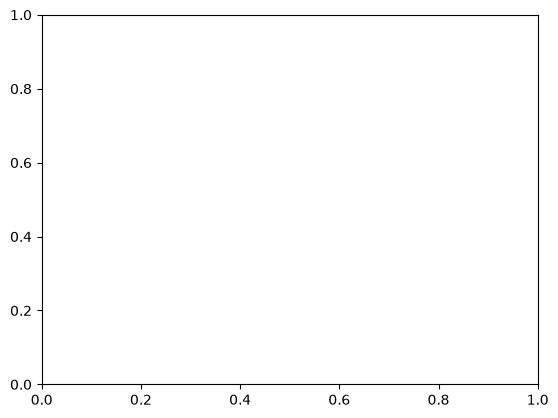

In [3]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots()

df["city"].value_counts().plot(kind="bar")

ax.set_title("Antal användare per stad")
ax.set_xlabel("Stad")
ax.set_ylabel("Antal")
ax.grid(True, axis="y")
plt.xticks(rotation=0)
plt.tight_layout()

### Uppgift 19 – Fördelning (histogram)
- Rita ett **histogram** av `steps` (välj ett rimligt antal bins, t.ex. 20).
- Lägg till titel/axlar och ett rutnät.
- Skriv en kort kommentar i kod (t.ex. om fördelningen ser skev ut).

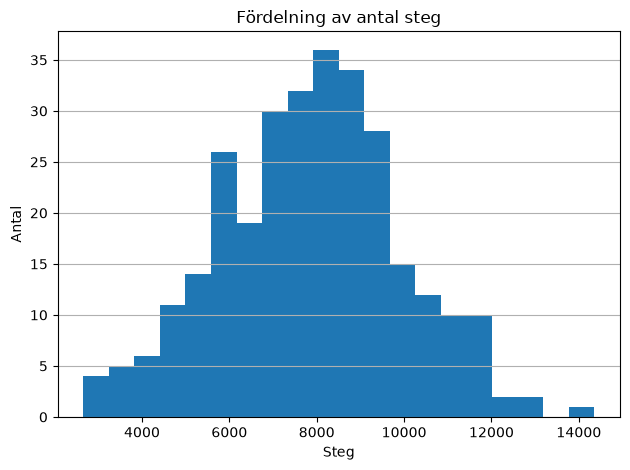

In [ ]:
fig, ax = plt.subplots()
ax.hist(df["steps"].dropna(), bins=20)
ax.set_title("Fördelning av antal steg")
ax.set_xlabel("Steg")
ax.set_ylabel("Antal")
ax.grid(True, axis="y")
plt.tight_layout()  # ser ganska normalfördelat ut, ett extremvärde endast vid 14000 steg

### Uppgift 20 – Samband (scatter)
- Skapa en **scatterplot** med `steps` på x-axeln och `calories` på y-axeln.
- Lägg till titel, axelrubriker och rutnät.
- Skriv en kort kommentar om du tycker sambandet verkar positivt/negativt/svagt.

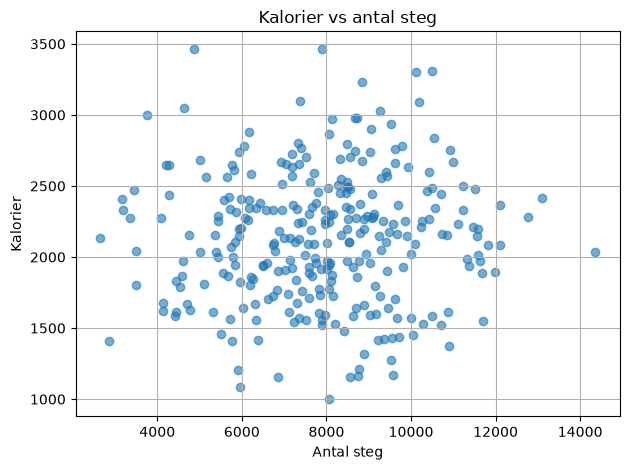

In [ ]:
fig, ax = plt.subplots()
ax.scatter(df["steps"], df["calories"], alpha=0.6)
ax.set_title("Kalorier vs antal steg")
ax.set_xlabel("Antal steg")
ax.set_ylabel("Kalorier")
ax.grid(True)
plt.tight_layout() 
# svagt samband, närapå noll korrelation.
# avviker starkt från förväntningen där fler steg borde generera fler förbrukade kalorier 
# mycket troligt dåligt simulerad data i detta fall, eller att calories inte representerar förbrukade kalorier.
# även att någon skulle kunna förbruka endast 1000 kalorier(eller inta kalorier om datan representerar detta) är inte biologiskt möjligt för överlevnad

### Uppgift 21 – Felsökning (plot)
Koden försöker rita ett histogram på en icke-existerande kolumn. Kör och rätta.
```python
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("week4_data.csv")
df["step"].plot(kind="hist", bins=10)
plt.show()
```
**Mål:** använd korrekt kolumn och visa grafen.

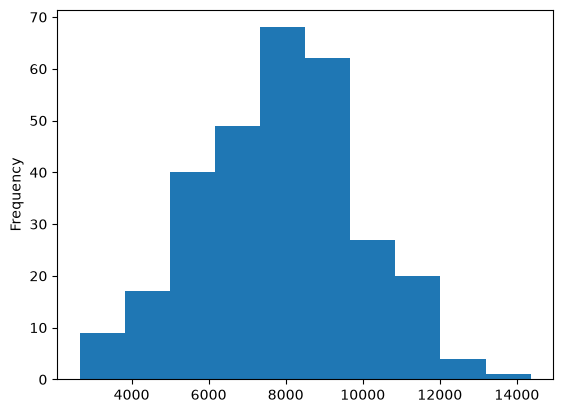

In [39]:
df = pd.read_csv("week4_data.csv")
df["steps"].plot(kind="hist", bins=10)
plt.show()

### Uppgift 22 – Mini-dashboard
Skapa tre figurer:
1. Histogram av `sleep_hours`,
2. Stapeldiagram med frekvenser för `gender`,
3. Scatter `steps` vs `screen_time`.

Lägg på titlar/axlar/rutnät och spara **en** figur till fil (valfritt filnamn).

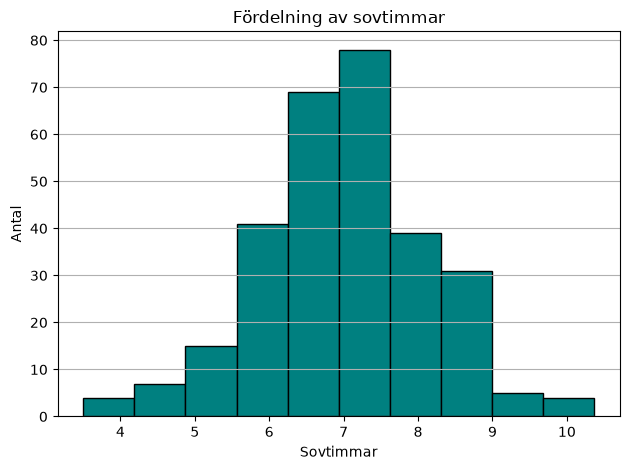

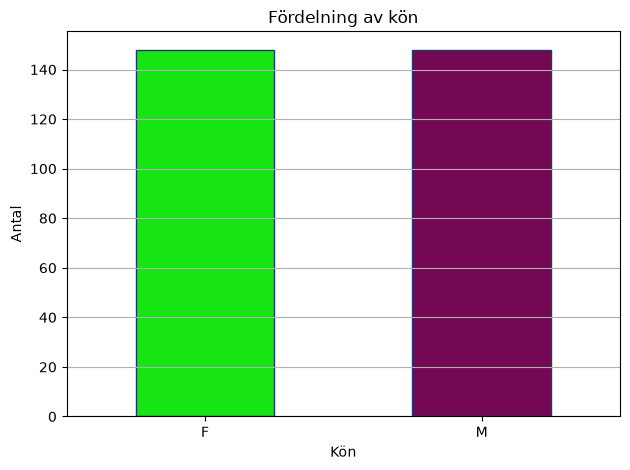

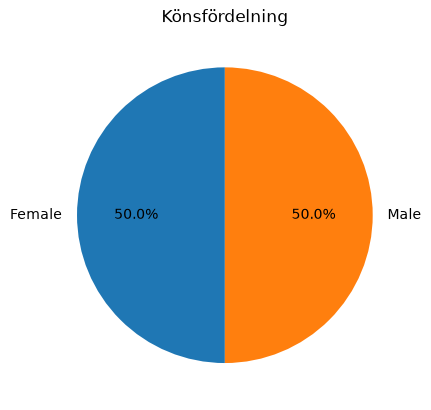

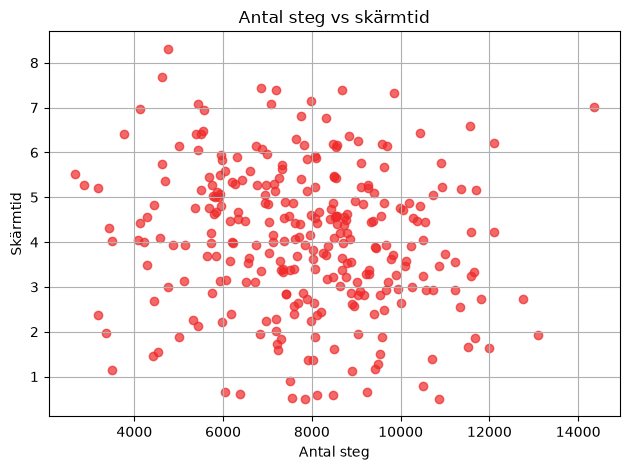

In [12]:
# histogram for sleep_hours
fig, ax = plt.subplots()
ax.hist(df["sleep_hours"].dropna(), bins=10, color="teal", edgecolor="black")
ax.set_title("Fördelning av sovtimmar")
ax.set_xlabel("Sovtimmar")
ax.set_ylabel("Antal")
ax.grid(True, axis="y")
plt.tight_layout()

# bar chart for gender, inte bäst för 2 värden. jag kör en piechart också för detta
fig, ax = plt.subplots()
df["gender"].value_counts().plot(kind="bar", color=["#17e413", "#740854"], edgecolor="#1B3A6E")
ax.set_title("Fördelning av kön")
ax.set_xlabel("Kön")
ax.set_ylabel("Antal")
ax.grid(True, axis="y")
plt.xticks(rotation=0)
plt.tight_layout()

# pie chart bättre diagram för fördelning av 2st variationer
# autopct="%1.1f%%" Visar procent med en decimal (t.ex. 52.3%), startangle rotates the chart
# .rename({}) tar en dictionary som argument {"gammalt_namn": "nytt_namn", "gammalt_namn2": "nytt_namn2"} 
# döper om i detta fall M till Male och F till Female.
# colormaps["okabe_ito"] är känd lista för färgblinda, vetenskaplig standardandra exempel cividis & coolwarm.
fig, ax = plt.subplots()
df["gender"].value_counts().rename({"F":"Female","M":"Male"}).plot(kind="pie", ax=ax, autopct="%1.1f%%", startangle=90, color=plt.colormaps["okabe_ito"].colors[:2])
ax.set_title("Könsfördelning") 
plt.savefig("files/piechart_gender.png", dpi=150)
plt.show()


# scatterplot for steps vs screen_time
fig, ax = plt.subplots()
ax.scatter(df["steps"], df["screen_time"], alpha=0.7, color="#EF2929")
ax.set_title("Antal steg vs skärmtid")
ax.set_xlabel("Antal steg")
ax.set_ylabel("Skärmtid")
ax.grid(True)
plt.tight_layout()